In [1]:
%pip install pandas matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\klenk\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "article/evaluation/main_metrics_all_conditions.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Открой папку RMT и положи notebook в её корень.")
DATA = ROOT / "article/evaluation"
OUT = ROOT / "visualizations"
OUT.mkdir(exist_ok=True)

means = pd.read_csv(DATA / "main_metrics_all_conditions.csv")
runs = pd.read_csv(DATA / "per_run_metrics.csv")
intervals = json.loads((DATA / "absolute_metric_intervals.json").read_text())
counts = pd.read_csv(DATA / "unseen_confusion_counts.csv")
MODELS = ["resnet50", "clip_linear"]
NAMES = {"resnet50": "ResNet-50", "clip_linear": "CLIP linear"}
COLORS = {"resnet50": "#17334D", "clip_linear": "#087F82"}
CONDITIONS = ["original", "jpeg65", "resize112"]
LABELS = ["Original", "JPEG 65", "Resize 112"]
plt.rcParams.update({"font.size": 10, "pdf.fonttype": 42,
                     "axes.spines.top": False, "axes.spines.right": False})

def finish(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved: visualizations/{name}.png and .pdf")



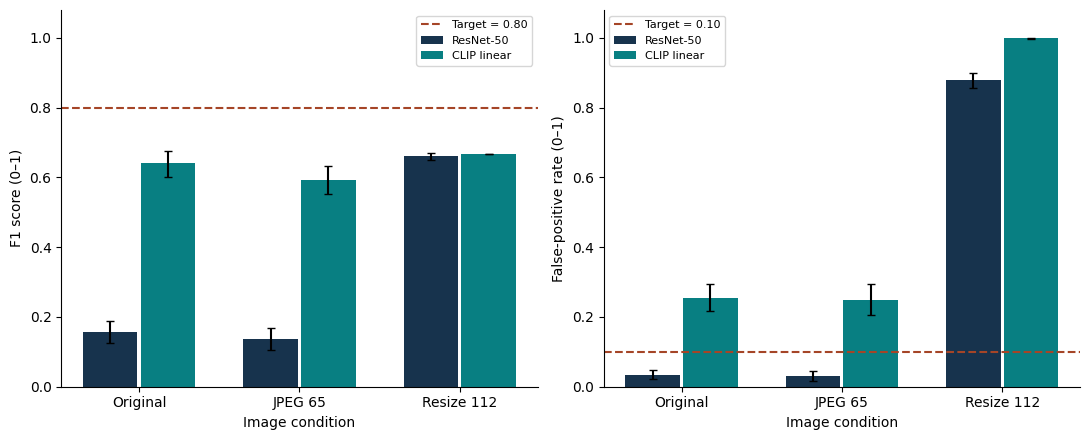

Saved: visualizations/01_unseen_f1_fpr.png and .pdf


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
x = np.arange(len(CONDITIONS))
for ax, metric, target in zip(axes, ["f1", "fpr"], [0.80, 0.10]):
    for i, model in enumerate(MODELS):
        points = np.array([intervals[f"unseen_{model}_{c}_{metric}"] for c in CONDITIONS])
        values = points[:, 0]
        errors = np.maximum(0, np.vstack([values - points[:, 1], points[:, 2] - values]))
        ax.bar(x + (i - 0.5) * 0.36, values, width=0.34,
               yerr=errors, capsize=3, color=COLORS[model], label=NAMES[model])
    ax.axhline(target, color="#A54527", linestyle="--", label=f"Target = {target:.2f}")
    ax.set(xticks=x, xticklabels=LABELS, ylim=(0, 1.08), xlabel="Image condition",
           ylabel="F1 score (0–1)" if metric == "f1" else "False-positive rate (0–1)")
    ax.legend(fontsize=8)
finish(fig, "01_unseen_f1_fpr")


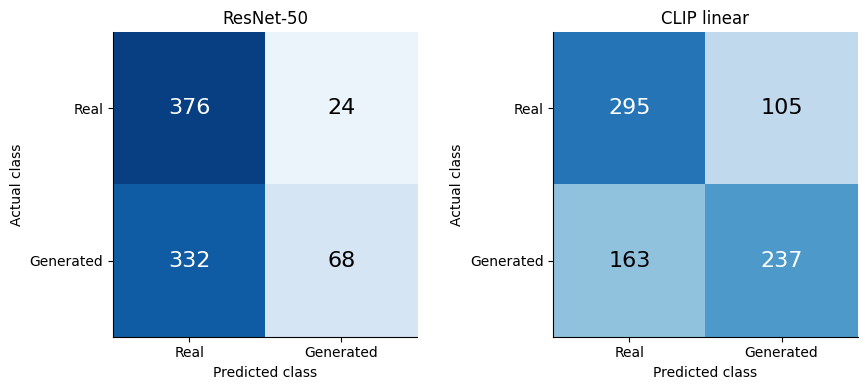

Saved: visualizations/02_confusion_seed42.png and .pdf


In [3]:
SEED = 42
assert SEED in [42, 43, 44]
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, model in zip(axes, MODELS):
    row = counts[(counts["model"] == model) & (counts["seed"] == SEED)].iloc[0]
    matrix = np.array([[int(row["tn"]), int(row["fp"])],
                       [int(row["fn"]), int(row["tp"])]])
    assert matrix.sum() == 800 and np.all(matrix.sum(axis=1) == 400)
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=400)
    for y in range(2):
        for x in range(2):
            ax.text(x, y, str(matrix[y, x]), ha="center", va="center", fontsize=16,
                    color="white" if matrix[y, x] > 200 else "black")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Real", "Generated"],
           yticklabels=["Real", "Generated"], xlabel="Predicted class",
           ylabel="Actual class", title=NAMES[model])
finish(fig, f"02_confusion_seed{SEED}")
